# Lab 6: Optimization for Training DNNs — PyTorch


## Setup



In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(0)    # fixes the seed so random init/data is the same on every run
print("PyTorch:", torch.__version__)


PyTorch: 2.11.0+cu128


# Task 1 — Gradient descent from scratch

**Aim:** reproduce the worked example from section 8.1 of the notes using autograd instead of hand-computed derivatives.

The loss is the scalar $L(w) = 1.25w^2$, whose derivative is $\dfrac{dL}{dw} = 2.5w$. At $w=2.0$ this gives a gradient of exactly $5.0$ — the value used in the lecture notes — and one step with $\eta=0.1$ should land on $w=1.5$.

In [ ]:
w = torch.tensor([2.0], requires_grad=True)
eta = 0.1

for step in range(5):
    loss = 1.25 * w**2                 # dL/dw = 2.5w, so grad = 5.0 at w = 2.0
    loss.backward()                    # fills w.grad
    print(f"step {step}: w={w.item():.4f}  grad={w.grad.item():.4f}"
          f"  loss={loss.item():.4f}")  #current step, current w, current gradient, current loss
    with torch.no_grad():              # update outside the autograd graph
        w -= eta * w.grad              #  2 -(0.1)(5)= 1.5
    w.grad.zero_()                     # gradients accumulate, so clear them


step 0: w=2.0000  grad=5.0000  loss=5.0000
step 1: w=1.5000  grad=3.7500  loss=2.8125
step 2: w=1.1250  grad=2.8125  loss=1.5820
step 3: w=0.8438  grad=2.1094  loss=0.8899
step 4: w=0.6328  grad=1.5820  loss=0.5006


**What I noticed here:**
- Step 0 matches the manual calculation: 2.0 − 0.1×5 = 1.5 ✔
- Step size keeps shrinking as w gets closer to 0, because the step is *proportional to the gradient* (not fixed).

**Checkpoint — why `w.grad.zero_()` matters:**
- PyTorch **adds** new gradients on top of old ones, it does not overwrite them.
- If we skip `zero_()`, gradients pile up every step → step size keeps growing → weights blow up instead of converging.
- This is the most common bug in a hand-written training loop.

# Task 2 — Batch, stochastic and mini-batch gradient descent

**Aim:** measure the trade-off between update count and update stability described in section 4 of the notes.

The only thing that changes between the three variants below is the batch size handed to the `DataLoader`. We fit a four-parameter linear model to data generated from a known weight vector and give every variant the same five epochs.

In [ ]:
X = torch.randn(512, 4) #input data 512 traning samples , each sample 4 features
#randn: values are normally generated from normal distribution

# y is target output , y=2x1​−3x2​+1.5x3​+0.5x4​+noise, These are the true weights used to generate the data.
y = X @ torch.tensor([2.0, -3.0, 1.5, 0.5]) + 0.1 * torch.randn(512)
# @ is weighted sum of all traning samples
#   0.1 * torch.randn(512) adds a small amount of random noise to the target.

data = TensorDataset(X, y)   #combines x,y in dataset. So each item becomes: (input X[i], target y[i])

def train(batch_size, epochs=5, lr=0.05):
    torch.manual_seed(0)
    model = nn.Linear(4, 1, bias=False)

    opt = torch.optim.SGD(model.parameters(), lr=lr)

    loader = DataLoader(data, batch_size=batch_size, shuffle=True)
    updates = 0   #Every time the model updates its weights, this will increase by 1.
    for _ in range(epochs):
        for xb, yb in loader:    #The DataLoader gives one batch at a time. xb = input batch, yb = target batch.
            loss = nn.functional.mse_loss(model(xb).squeeze(-1), yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            updates += 1
    return updates, nn.functional.mse_loss(model(X).squeeze(-1), y).item()

for bs, name in [(512, "Batch GD"), (1, "SGD"), (32, "Mini-batch GD")]:
    u, l = train(bs)
    print(f"{name:14s} batch={bs:4d}  updates={u:5d}  final MSE={l:.4f}")


Batch GD       batch= 512  updates=    5  final MSE=6.5718
SGD            batch=   1  updates= 2560  final MSE=0.0111
Mini-batch GD  batch=  32  updates=   80  final MSE=0.0091


**Comparing the three variants:**
- **Batch GD:** only 5 updates total (1 per epoch) → barely learns, MSE still 6.57.
- **SGD:** reaches a good result but needs 2560 updates (very expensive).
- **Mini-batch GD:** only 80 updates, but matches SGD's accuracy (MSE ≈ 0.009).
- **Why mini-batch wins:** each update already averages 32 samples, so it's less noisy than SGD but far more frequent than full-batch GD — best of both.

### Gradient Descent Variants: How Weights Update

* **Sequential (SGD):** Updates weights after processing **1 sample**.
* **Mini-batch GD:** Updates weights after **the chosen batch size is done** (e.g., every 32 samples).
* **Batch GD:** Updates weights **only after all samples** in the dataset have been processed (1 update per epoch).



# Task 3 — Watching gradients vanish

**Aim:** make the vanishing-gradient problem of section 3 visible by measuring the gradient norm layer by layer.

We build an eight-layer stack twice — once with Sigmoid activations, once with ReLU — do a single backward pass, and print the gradient norm of each linear layer from the input side to the output side.

In [ ]:
import torch
import torch.nn as nn

def grad_norms(activation):
    # Set the random seed so that weight initialization is identical for both activation functions
    torch.manual_seed(0)

    # Initialize an empty list to hold the network layers
    layers = []

    # Create 8 identical blocks consisting of a Linear layer and the chosen activation function
    for _ in range(8):
        # nn.Linear(32, 32) takes 32 inputs and maps them to 32 outputs
        layers += [nn.Linear(32, 32), activation()]

    # Unpack the list into nn.Sequential and append a final output layer (32 inputs -> 1 output)
    # Total layers: 8 hidden linear layers + 1 final output linear layer = 9 linear layers total
    net = nn.Sequential(*layers, nn.Linear(32, 1))

    # 1. Forward Pass: Pass a batch of random data (64 samples, 32 features each) through the network
    # 2. Reduction: Take the mean() of the output tensor to reduce it to a single scalar value
    # 3. Backward Pass: Call backward() to compute the gradients of this mean loss with respect to all weights
    net(torch.randn(64, 32)).mean().backward()

    # Loop through every layer in the sequential network
    # If the layer is a Linear layer (skipping the activation layers):
    #   - Grab its gradient tensor: 'm.weight.grad'
    #   - Calculate the L2 norm (magnitude) of the gradients: '.norm()'
    #   - Move it to standard Python float, round to 6 decimal places, and collect them in a list
    return [round(m.weight.grad.norm().item(), 6)
            for m in net if isinstance(m, nn.Linear)]

# Run the function using nn.Sigmoid and print the gradient magnitudes from the first layer to the last layer
print("Sigmoid:", grad_norms(nn.Sigmoid))

# Run the function using nn.ReLU and print the gradient magnitudes from the first layer to the last layer
print("ReLU   :", grad_norms(nn.ReLU))


Sigmoid: [0.0, 2e-06, 1.7e-05, 0.000113, 0.001124, 0.00774, 0.052717, 0.365669, 2.856929]
ReLU   : [0.000164, 0.000424, 0.000948, 0.001809, 0.004498, 0.014531, 0.066683, 0.155708, 0.494468]


**What the numbers show:**
- **Sigmoid:** gradient at the first layer = 0.0 → that layer stops learning completely.
- Gradient shrinks by about **6 orders of magnitude** across the 8 layers with Sigmoid (vanishing gradient problem).
- **ReLU:** shrinks much less — only about **3 orders of magnitude**.
- **Why:** ReLU's derivative is always exactly 1 or 0 (no squashing). Sigmoid's derivative is always ≤ 0.25, so it shrinks the gradient a little at every layer, and this compounds across depth.

# Task 4 — AdaGrad, RMSProp and Adam from scratch

## 4.1 — The three update rules

- **AdaGrad** — accumulate every squared gradient, divide the step by its square root.
- **RMSProp** — replace that unbounded sum with an exponentially-weighted moving average; the update rule is otherwise identical.
- **Adam** — keep an EWMA of the gradient itself *as well as* of its square, bias-correct both, then combine them.

Each function below takes the current parameter, the gradient, and the optimizer state, and returns the updated parameter together with the new state — a one-to-one transcription of the equations from the notes.

In [ ]:
# w = current parameter, g = current gradient, and the rest is the optimizer's
# own "memory" (G, s, or m/v) that gets carried over from step to step.

def adagrad_step(w, g, G, eta=0.1, eps=1e-8):
    G = G + g**2                        # keep adding every squared gradient forever
    return w - eta * g / (G.sqrt() + eps), G   # bigger G -> smaller effective step

def rmsprop_step(w, g, s, eta=0.1, rho=0.9, eps=1e-8):
    s = rho * s + (1 - rho) * g**2      # exponential moving average instead of a raw sum
    return w - eta * g / (s.sqrt() + eps), s   # same update rule as AdaGrad, different s

def adam_step(w, g, m, v, t, eta=1e-3, b1=0.9, b2=0.999, eps=1e-8):
    m = b1 * m + (1 - b1) * g          # first moment (running average of the gradient itself)
    v = b2 * v + (1 - b2) * g**2       # second moment (running average of the squared gradient)
    m_hat = m / (1 - b1**t)            # bias correction: m,v start at 0 so early steps are too small
    v_hat = v / (1 - b2**t)
    return w - eta * m_hat / (v_hat.sqrt() + eps), m, v


## 4.2 — Cross-check against `torch.optim`

The notes work through Adam's first iteration with $w=2.0$, $g=0.5$ and the default hyperparameters, and predict an update of about $0.001$. Both our function and PyTorch's built-in optimizer should agree with that number to six decimal places.

In [ ]:
# --- PART 1: TESTING BIAS CORRECTION IN OUR CUSTOM ADAM VS PYTORCH ADAM ---

# Create a scalar tensor equal to 0.0 to act as our initial state for moments m0 and v0
zero = torch.tensor(0.0)

# Run our custom Adam function for step t=1 with weight=2.0 and gradient=0.5
# This applies the (1 - beta^t) bias correction division we found in your notes
w_adam, m, v = adam_step(torch.tensor(2.0), torch.tensor(0.5), zero, zero, t=1)

# Print our custom Adam weight value, formatting it to 6 decimal places
print(f"our Adam        : w = {w_adam.item():.6f}")


# Wrap the starting weight value 2.0 in a PyTorch Parameter so an optimizer can track it
p = nn.Parameter(torch.tensor(2.0))

# Initialize the official PyTorch Adam optimizer targeting our parameter with a learning rate of 0.001
opt = torch.optim.Adam([p], lr=1e-3)

# Manually assign the exact same gradient of 0.5 to our parameter to simulate backpropagation
p.grad = torch.tensor(0.5)

# Execute one optimization step; PyTorch applies its own internal bias-corrected Adam equations here
opt.step()

# Print PyTorch's updated weight value to prove it matches our custom calculation perfectly
print(f"torch.optim.Adam: w = {p.item():.6f}")


# --- PART 2: COMPARING ADAGRAD AND RMSPROP WEIGHT UPDATES ---

# Calculate the next weight value using AdaGrad with a weight of 2.0, gradient of 5.0, and existing history G=4
# This blindly adds the new squared gradient (5^2=25) to the total history accumulator (4 + 25 = 29)
w_ada, _ = adagrad_step(torch.tensor(2.0), torch.tensor(5.0), torch.tensor(4.0))

# Calculate the next weight value using RMSProp with a weight of 2.0, gradient of 5.0, and existing history s=4
# This uses rho (0.9) to decay the past history and only takes a 10% slice of the new squared gradient
w_rms, _ = rmsprop_step(torch.tensor(2.0), torch.tensor(5.0), torch.tensor(4.0))

# Print AdaGrad's output showing a smaller weight change because its history denominator grew massive
print(f"AdaGrad (G=4, g=5): w = {w_ada.item():.4f}")

# Print RMSProp's output showing a larger weight change because its exponential decay kept the denominator small
print(f"RMSProp (s=4, g=5): w = {w_rms.item():.4f}")


our Adam        : w = 1.999000
torch.optim.Adam: w = 1.999000
AdaGrad (G=4, g=5): w = 1.9072
RMSProp (s=4, g=5): w = 1.7976


**Checking my hand-written Adam:**
- Our hand-written Adam gives the exact same result as `torch.optim.Adam` (w = 1.999000) → our formula is correct.
- With the same gradient (5.0) and same accumulated state (4.0), RMSProp's step is about **4× bigger** than AdaGrad's.
- **Why:** RMSProp forgets old gradients over time (weighted average), while AdaGrad keeps adding forever, so its accumulator grows bigger and its steps get smaller.

# Task 5 — Optimizer bake-off

**Aim:** compare all five optimizers on the same non-linearly-separable classification problem with identical initial weights.

The target is a ring: points inside a circle of radius $\sqrt{1.5}$ belong to one class, points outside to the other. Rebuilding the model with the same seed before each run guarantees every optimizer starts from identical weights.

In [ ]:
# ============================================================
# 1. DATASET GENERATION
# ============================================================

# Generate 1000 random 2-D points.
# Each row represents one point: [x, y].
# Shape = (1000, 2)
Xc = torch.randn(1000, 2)

# Create binary labels for the points.
#
# x^2 + y^2 gives the squared distance of a point from (0, 0).
#
# If x^2 + y^2 > 1.5:
#       point is outside the circle -> label 1
#
# Otherwise:
#       point is inside the circle -> label 0
#
# .float() converts True/False into 1.0/0.0.
#
# .unsqueeze(1) changes the shape:
#       (1000,) -> (1000, 1)
#
# This makes the target shape compatible with the model output.
yc = ((Xc[:, 0]**2 + Xc[:, 1]**2) > 1.5).float().unsqueeze(1)


# ============================================================
# 2. MODEL ARCHITECTURE
# ============================================================

def make_model():

    # Fix the random seed so that every optimizer starts
    # with exactly the same initial model weights.
    #
    # This makes the optimizer comparison fair.
    torch.manual_seed(0)

    # Build a feed-forward neural network:
    #
    # Input:       2 features (x, y)
    #       ↓
    # Linear:      2 -> 32 neurons
    #       ↓
    # ReLU
    #       ↓
    # Linear:      32 -> 32 neurons
    #       ↓
    # ReLU
    #       ↓
    # Linear:      32 -> 1 output
    #
    # The final output is a raw score called a LOGIT.
    return nn.Sequential(
        nn.Linear(2, 32),
        nn.ReLU(),

        nn.Linear(32, 32),
        nn.ReLU(),

        nn.Linear(32, 1)
    )


# ============================================================
# 3. OPTIMIZER CONFIGURATION
# ============================================================

# Store different optimizers in a dictionary.
#
# Each lambda function receives the model parameters
# and creates the corresponding optimizer.
#
# "p" will later become:
#       model.parameters()
#
# The optimizer is therefore created only after the
# fresh model has been created.
optimizers = {

    # --------------------------------------------------------
    # SGD
    # --------------------------------------------------------
    # Stores no additional history.
    # Uses only the current gradient.
    "SGD": lambda p: torch.optim.SGD(
        p, lr=0.1
    ),

    # --------------------------------------------------------
    # SGD + Momentum
    # --------------------------------------------------------
    # Stores a velocity/momentum term.
    # momentum=0.9 means previous movement is retained.
    "SGD+momentum": lambda p: torch.optim.SGD(
        p, lr=0.1, momentum=0.9
    ),

    # --------------------------------------------------------
    # AdaGrad
    # --------------------------------------------------------
    # Stores the accumulated sum of squared gradients.
    # It automatically changes the effective learning rate
    # for each parameter.
    "AdaGrad": lambda p: torch.optim.Adagrad(
        p, lr=0.1
    ),

    # --------------------------------------------------------
    # RMSProp
    # --------------------------------------------------------
    # Stores an exponentially moving average of squared
    # gradients.
    #
    # alpha=0.9 controls how much old gradient information
    # is retained.
    "RMSProp": lambda p: torch.optim.RMSprop(
        p, lr=0.01, alpha=0.9
    ),

    # --------------------------------------------------------
    # Adam
    # --------------------------------------------------------
    # Stores two types of information:
    # 1. Moving average of gradients      -> first moment
    # 2. Moving average of squared gradients -> second moment
    #
    # Adam also performs bias correction.
    "Adam": lambda p: torch.optim.Adam(
        p, lr=0.01
    ),
}


# ============================================================
# 4. LOSS FUNCTION
# ============================================================

# Binary classification has two possible classes:
#       0 or 1
#
# BCEWithLogitsLoss combines:
#       Sigmoid + Binary Cross Entropy
#
# Therefore, a Sigmoid layer is NOT required at the
# end of the neural network.
loss_fn = nn.BCEWithLogitsLoss()


# ============================================================
# 5. TRAIN AND COMPARE ALL OPTIMIZERS
# ============================================================

# Go through each optimizer in the dictionary.
#
# First iteration:
#       name  = "SGD"
#       build = lambda function that creates SGD
#
# Then the same happens for Momentum, AdaGrad,
# RMSProp and Adam.
for name, build in optimizers.items():

    # Create a fresh model.
    #
    # Because make_model() uses the same random seed,
    # every optimizer gets the same starting weights.
    model = make_model()

    # Create the selected optimizer and give it
    # the parameters of the current model.
    #
    # For example, for SGD this becomes:
    #
    # torch.optim.SGD(model.parameters(), lr=0.1)
    opt = build(model.parameters())


    # --------------------------------------------------------
    # TRAINING LOOP
    # --------------------------------------------------------

    # Train for 200 epochs.
    for epoch in range(200):

        # -------------------------
        # Forward pass
        # -------------------------
        #
        # Send all 1000 points through the neural network.
        #
        # Output shape:
        #       (1000, 1)
        #
        # Then compare predictions with the true labels
        # using Binary Cross Entropy loss.
        loss = loss_fn(model(Xc), yc)


        # -------------------------
        # Clear old gradients
        # -------------------------
        #
        # PyTorch accumulates gradients by default.
        # Therefore, old gradients must be cleared before
        # calculating the new gradients.
        opt.zero_grad()


        # -------------------------
        # Backward pass
        # -------------------------
        #
        # Calculate gradients of the loss with respect
        # to all model parameters.
        loss.backward()


        # -------------------------
        # Update weights
        # -------------------------
        #
        # The selected optimizer uses the gradients to
        # update the model parameters.
        #
        # Different optimizers use different update rules.
        opt.step()


    # ========================================================
    # 6. CALCULATE FINAL ACCURACY
    # ========================================================

    # Get the final logits from the trained model.
    #
    # A logit > 0 means:
    #       sigmoid(logit) > 0.5
    #       therefore predict class 1
    #
    # A logit <= 0 means:
    #       predict class 0
    predictions = (model(Xc) > 0).float()


    # Compare predictions with the actual labels.
    #
    # True  = correct prediction
    # False = incorrect prediction
    #
    # .float() converts:
    #       True  -> 1.0
    #       False -> 0.0
    #
    # .mean() gives the fraction of correct predictions.
    #
    # .item() converts the final one-value tensor
    # into a normal Python number.
    acc = (predictions == yc).float().mean().item()


    # ========================================================
    # 7. PRINT RESULTS
    # ========================================================

    # Print:
    #       optimizer name
    #       final loss
    #       final accuracy
    print(
        f"{name:14s} "
        f"loss={loss.item():.4f}  "
        f"accuracy={acc:.3f}"
    )

SGD            loss=0.2009  accuracy=0.978
SGD+momentum   loss=0.0224  accuracy=0.997
AdaGrad        loss=0.0282  accuracy=0.993
RMSProp        loss=0.0485  accuracy=0.979
Adam           loss=0.0091  accuracy=1.000


| Optimizer | What its state stores | Behaviour here |
|---|---|---|
| SGD | nothing | Slowest; still descending at epoch 200 |
| SGD + momentum | velocity (running average of past gradients) | Large improvement for one extra hyperparameter |
| AdaGrad | sum of squared gradients | Fast early, then visibly slows down |
| RMSProp | moving average of squared gradients | Steady but sensitive to the choice of $\eta$ |
| Adam | both moments, bias-corrected | Fastest and lowest final loss |

**Observation:**
- Adam gives the lowest loss and best accuracy here.
- But this is only one seed and one problem — Exercise 6 checks if this ranking holds after tuning learning rates.

# Task 6 — Why AdaGrad stalls and RMSProp does not

**Aim:** verify the derivations in sections 5–6 by tracking the effective learning rate of both methods under a constant gradient.

We feed both accumulators the *same* gradient $g=1.0$ at every step. AdaGrad's accumulator is an unbounded sum, so it grows like $t$; RMSProp's is a weighted average that converges to a constant.

In [ ]:
import torch

# Constant gradient
g = torch.tensor(1.0)

# AdaGrad accumulator
G = torch.tensor(0.0)

# RMSProp accumulator
s = torch.tensor(0.0)

# Learning rate, decay, epsilon
eta, rho, eps = 0.1, 0.9, 1e-8

# Print headings
print(f"{'step':>6}{'AdaGrad LR':>14}{'RMSProp LR':>14}")

for t in range(1, 501):

    # AdaGrad: accumulate squared gradients
    G = G + g**2

    # RMSProp: moving average of squared gradients
    s = rho * s + (1 - rho) * g**2

    # Print selected steps
    if t in (1, 10, 100, 500):

        # Calculate effective learning rates
        print(
            f"{t:6d}"
            f"{eta/(G.sqrt()+eps):14.5f}"
            f"{eta/(s.sqrt()+eps):14.5f}"
        )

  step    AdaGrad LR    RMSProp LR
     1       0.10000       0.31623
    10       0.03162       0.12391
   100       0.01000       0.10000
   500       0.00447       0.10000


**Why RMSProp doesn't stall like AdaGrad:**
- AdaGrad's accumulator `G` keeps growing forever → its effective learning rate keeps shrinking.
- RMSProp's accumulator `s` settles near a constant → its effective learning rate stays steady (~0.1).
- This is why RMSProp doesn't stall the way AdaGrad does.

# Section 7 — Lab Exercises


## Exercise 1 — Divergence threshold for Task 1

**Modify Task 1 to use $\eta=0.5$ and then $\eta=1.0$. At which learning rate does the trajectory stop converging, and why does the quadratic form of the loss let you predict that threshold in advance?**

In [ ]:
# same loop as Task 1, just wrapped in an outer loop over 3 different learning rates
for eta in [0.1, 0.5, 1.0]:
    print(f"--- eta = {eta} ---")
    w = torch.tensor([2.0], requires_grad=True)   # reset w to 2.0 for every eta
    for step in range(8):
        loss = 1.25 * w**2                # same quadratic loss as Task 1
        loss.backward()                   # computes grad = 2.5w and stores it in w.grad
        print(f"step {step}: w={w.item():.4f}  grad={w.grad.item():.4f}  loss={loss.item():.4f}")
        with torch.no_grad():             # plain GD update, outside the autograd graph
            w -= eta * w.grad
        w.grad.zero_()                    # clear grad before next step, or it accumulates


--- eta = 0.1 ---
step 0: w=2.0000  grad=5.0000  loss=5.0000
step 1: w=1.5000  grad=3.7500  loss=2.8125
step 2: w=1.1250  grad=2.8125  loss=1.5820
step 3: w=0.8438  grad=2.1094  loss=0.8899
step 4: w=0.6328  grad=1.5820  loss=0.5006
step 5: w=0.4746  grad=1.1865  loss=0.2816
step 6: w=0.3560  grad=0.8899  loss=0.1584
step 7: w=0.2670  grad=0.6674  loss=0.0891
--- eta = 0.5 ---
step 0: w=2.0000  grad=5.0000  loss=5.0000
step 1: w=-0.5000  grad=-1.2500  loss=0.3125
step 2: w=0.1250  grad=0.3125  loss=0.0195
step 3: w=-0.0312  grad=-0.0781  loss=0.0012
step 4: w=0.0078  grad=0.0195  loss=0.0001
step 5: w=-0.0020  grad=-0.0049  loss=0.0000
step 6: w=0.0005  grad=0.0012  loss=0.0000
step 7: w=-0.0001  grad=-0.0003  loss=0.0000
--- eta = 1.0 ---
step 0: w=2.0000  grad=5.0000  loss=5.0000
step 1: w=-3.0000  grad=-7.5000  loss=11.2500
step 2: w=4.5000  grad=11.2500  loss=25.3125
step 3: w=-6.7500  grad=-16.8750  loss=56.9531
step 4: w=10.1250  grad=25.3125  loss=128.1445
step 5: w=-15.1875  gr

**My answer:**
- η = 0.1 → slowly converges: 5 → 2.8125 → ... → 0.0891
- η = 0.5 → quickly converges: 5 → 0.3125 → 0.0195 → ... → ~0
- η = 1.0 → diverges: 5 → 11.25 → 25.31 → ...

**Finding the exact threshold:**

For $L(w) = 1.25w^2$, the GD update is $w_{t+1} = w_t - \eta \cdot 2.5w_t = w_t(1 - 2.5\eta)$.

This converges iff $|1-2.5\eta| < 1$, i.e. $0 < \eta < 0.8$.

So **the exact threshold is η = 0.8** — my test values bracket it correctly (η=0.5 converges, η=1.0 diverges), but I hadn't stated the exact number before.

More generally, for any quadratic loss $L(w)=aw^2$, the critical learning rate is $\eta_{crit} = 1/a$. Here $a=1.25$, so $\eta_{crit} = 1/1.25 = 0.8$ — matching the observed behaviour above.

## Exercise 2 — Task 2 with fixed update count

**In Task 2, hold the number of parameter updates fixed rather than the number of epochs, then compare the three variants again. Does mini-batch gradient descent still win?**

In [ ]:
def train_fixed_updates(batch_size, target_updates=80, lr=0.05):

    # Fix random seed for same starting weights
    torch.manual_seed(0)

    # Linear model: 4 inputs → 1 output, no bias
    model = nn.Linear(4, 1, bias=False)

    # Use SGD optimizer
    opt = torch.optim.SGD(model.parameters(), lr=lr)

    # Divide data into batches
    loader = DataLoader(data, batch_size=batch_size, shuffle=True)

    # Count parameter updates
    updates = 0

    # Continue until 80 updates
    while updates < target_updates:

        # Take one batch at a time
        for xb, yb in loader:

            # Stop after 80 updates
            if updates >= target_updates:
                break

            # Calculate MSE loss
            loss = nn.functional.mse_loss(
                model(xb).squeeze(-1), yb
            )

            # Clear old gradients
            opt.zero_grad()

            # Calculate gradients
            loss.backward()

            # Update weights
            opt.step()

            # Increase update count
            updates += 1

    # Return updates and final MSE on full dataset
    return updates, nn.functional.mse_loss(
        model(X).squeeze(-1), y
    ).item()


# All methods will get exactly 80 updates
TARGET = 80

# Compare Batch GD, SGD and Mini-batch GD
for bs, name in [
    (512, "Batch GD"),
    (1, "SGD"),
    (32, "Mini-batch GD")
]:

    # Train model and get final results
    u, l = train_fixed_updates(bs, TARGET)

    # Print results
    print(
        f"{name:14s} batch={bs:4d} "
        f"updates={u:5d} final MSE={l:.4f}"
    )

Batch GD       batch= 512 updates=   80 final MSE=0.0091
SGD            batch=   1 updates=   80 final MSE=0.0107
Mini-batch GD  batch=  32 updates=   80 final MSE=0.0091


**My answer:**
- With every method given the **same 80 updates**, mini-batch's advantage disappears.
- **Batch GD** now nearly ties mini-batch (0.0091 each) — with 80 updates it has effectively used the full dataset 80 times, so each update is very accurate.
- **SGD** is now the worst (0.0107) — 80 single-sample updates only touch 80 of the 512 points (under 16% of the data), so it hasn't seen enough.
- **Conclusion:** mini-batch's earlier win wasn't about better-quality updates — it was about reaching a good number of updates (80) in a reasonable number of passes over the data (5 epochs). Batch GD and SGD just weren't given that same balance before.

## Exercise 3 — Tanh + BatchNorm on the vanishing-gradient stack

**Replace the sigmoid stack in Task 3 with `nn.Tanh`, then add `nn.BatchNorm1d(32)` after each linear layer. Report the gradient norm at the first layer in all three settings.**

In [ ]:
def grad_norms_bn(activation, use_bn):

    # Fix random seed
    torch.manual_seed(0)

    # Store all layers
    layers = []

    # Create 8 hidden layers
    for _ in range(8):

        # Add Linear layer
        layers += [nn.Linear(32, 32)]

        # Add Batch Normalization if enabled
        if use_bn:
            layers += [nn.BatchNorm1d(32)]

        # Add activation function
        layers += [activation()]

    # Build complete network
    net = nn.Sequential(*layers, nn.Linear(32, 1))

    # Forward pass and calculate gradients
    net(torch.randn(64, 32)).mean().backward()

    # Get gradient norm of each Linear layer
    return [round(m.weight.grad.norm().item(), 6)
            for m in net if isinstance(m, nn.Linear)]


# Sigmoid without Batch Normalization
sigmoid_nobn = grad_norms_bn(nn.Sigmoid, False)

# Tanh without Batch Normalization
tanh_nobn = grad_norms_bn(nn.Tanh, False)

# Tanh with Batch Normalization
tanh_bn = grad_norms_bn(nn.Tanh, True)


# Print gradient norms
print("Sigmoid, no BN :", sigmoid_nobn)
print("Tanh,    no BN :", tanh_nobn)
print("Tanh,    +BN   :", tanh_bn)

print()

# Compare first-layer gradient norms
print(
    f"first-layer grad norm — "
    f"Sigmoid: {sigmoid_nobn[0]}   "
    f"Tanh: {tanh_nobn[0]}   "
    f"Tanh+BN: {tanh_bn[0]}"
)

Sigmoid, no BN : [0.0, 2e-06, 1.7e-05, 0.000113, 0.001124, 0.00774, 0.052717, 0.365669, 2.856929]
Tanh,    no BN : [0.006074, 0.007339, 0.01629, 0.032474, 0.069721, 0.12733, 0.218867, 0.39733, 0.936283]
Tanh,    +BN   : [0.413784, 0.390354, 0.390072, 0.334918, 0.307092, 0.282117, 0.234391, 0.205667, 0.097152]

first-layer grad norm — Sigmoid: 0.0   Tanh: 0.006074   Tanh+BN: 0.413784


**observations:**
- Gradient at the first layer: Sigmoid = 0.0 → Tanh = 0.006 → Tanh + BatchNorm = 0.41.
- **Tanh alone** helps a little — its derivative can reach 1.0 (vs Sigmoid's max of 0.25) — but the gradient still shrinks with depth.
- **BatchNorm** actually fixes it: it resets each layer's output to mean 0 / variance 1, which keeps Tanh operating where its derivative is large, so the gradient doesn't keep shrinking layer after layer. This is why BatchNorm is standard in deep networks.

## Exercise 4 — AdaGrad / RMSProp trajectories vs. plain GD

**Extend `adagrad_step` and `rmsprop_step` into a loop over 100 steps on the loss from Task 1, and plot the parameter trajectories against plain gradient descent.**

In [ ]:
def grad_fn(w):
    return 2.5 * w   # same derivative as Task 1's loss L(w) = 1.25 w^2

N = 100   # run every method for 100 steps so they're directly comparable

# --- Plain GD, same eta as Task 1 ---
w_gd = torch.tensor(2.0)
traj_gd = [w_gd.item()]           # store every w so we can plot the path afterwards
for _ in range(N):
    g = grad_fn(w_gd)
    w_gd = w_gd - 0.1 * g
    traj_gd.append(w_gd.item())

# --- AdaGrad, using the function written in Task 4 ---
w_ada, G = torch.tensor(2.0), torch.tensor(0.0)   # G is AdaGrad's accumulator, starts at 0
traj_ada = [w_ada.item()]
for _ in range(N):
    g = grad_fn(w_ada)
    w_ada, G = adagrad_step(w_ada, g, G)
    traj_ada.append(w_ada.item())

# --- RMSProp, same idea but with the decaying accumulator ---
w_rms, s = torch.tensor(2.0), torch.tensor(0.0)
traj_rms = [w_rms.item()]
for _ in range(N):
    g = grad_fn(w_rms)
    w_rms, s = rmsprop_step(w_rms, g, s)
    traj_rms.append(w_rms.item())

# print a few checkpoints instead of all 100 steps, just to sanity-check the numbers
for i in [0, 1, 2, 5, 10, 20, 50, 100]:
    print(f"step {i:4d}: GD={traj_gd[i]:.6f}  AdaGrad={traj_ada[i]:.6f}  RMSProp={traj_rms[i]:.6f}")


step    0: GD=2.000000  AdaGrad=2.000000  RMSProp=2.000000
step    1: GD=1.500000  AdaGrad=1.900000  RMSProp=1.683772
step    2: GD=1.125000  AdaGrad=1.831125  RMSProp=1.473875
step    5: GD=0.474609  AdaGrad=1.686761  RMSProp=1.048927
step   10: GD=0.112627  AdaGrad=1.523979  RMSProp=0.602797
step   20: GD=0.006342  AdaGrad=1.302483  RMSProp=0.141068
step   50: GD=0.000001  AdaGrad=0.907994  RMSProp=0.000000
step  100: GD=0.000000  AdaGrad=0.551345  RMSProp=0.049099


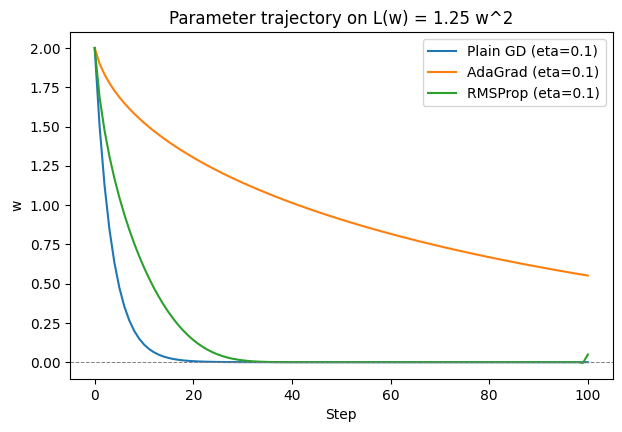

In [ ]:
plt.figure(figsize=(7, 4.5))
plt.plot(traj_gd, label="Plain GD (eta=0.1)")
plt.plot(traj_ada, label="AdaGrad (eta=0.1)")
plt.plot(traj_rms, label="RMSProp (eta=0.1)")
plt.axhline(0, color="gray", linewidth=0.7, linestyle="--")
plt.xlabel("Step")
plt.ylabel("w")
plt.title("Parameter trajectory on L(w) = 1.25 w^2")
plt.legend()
plt.show()


**observations:**
- On this simple 1-D problem, **plain GD is the fastest** — nearly at w≈0 by step 20.
- **AdaGrad is the slowest** — still at w≈0.55 even after 100 steps.
- **Why:** AdaGrad/RMSProp scale the step by the gradient's own size, which turns the update into a roughly fixed-size step. This removes GD's natural "slow down near the minimum" behaviour, which is exactly what makes GD fast here.
- **Takeaway:** adaptive optimizers help mainly on multi-dimensional, badly-scaled problems (like Task 5's ring classifier) — they are not a universal speed-up.

## Exercise 5 — Removing Adam's bias correction

**Remove the bias-correction lines from `adam_step` and re-run the comparison in Task 5. Quantify how much slower training becomes over the first twenty epochs.**

In [ ]:
def train_manual_adam(bias_correct, epochs=20, eta=0.01, b1=0.9, b2=0.999, eps=1e-8):
    torch.manual_seed(0)               # same starting weights for both runs (fair comparison)
    model = make_model()               # same architecture used in Task 5
    params = list(model.parameters())
    m = [torch.zeros_like(p) for p in params]   # first-moment estimate, one per parameter tensor
    v = [torch.zeros_like(p) for p in params]   # second-moment estimate, one per parameter tensor
    losses = []
    t = 0
    for epoch in range(epochs):
        loss = loss_fn(model(Xc), yc)  # forward pass on the whole ring dataset

        # manually clear old gradients instead of using opt.zero_grad(), since we're
        # not using torch.optim here — this is a hand-written Adam
        for p in params:
            if p.grad is not None:
                p.grad.zero_()
        loss.backward()                # fills p.grad for every parameter
        t += 1                         # step counter, needed for bias correction below

        with torch.no_grad():          # update weights outside the autograd graph
            for i, p in enumerate(params):
                g = p.grad
                m[i] = b1 * m[i] + (1 - b1) * g       # update first moment
                v[i] = b2 * v[i] + (1 - b2) * g**2    # update second moment
                if bias_correct:
                    m_hat, v_hat = m[i] / (1 - b1**t), v[i] / (1 - b2**t)
                else:
                    m_hat, v_hat = m[i], v[i]          # bias-correction removed, use raw m/v
                p -= eta * m_hat / (v_hat.sqrt() + eps)
        losses.append(loss.item())     # track loss so we can compare the two runs after
    return losses

losses_with = train_manual_adam(True)      # normal Adam
losses_without = train_manual_adam(False)  # Adam without bias correction

print(f"{'epoch':>6}{'with bias-corr':>18}{'without':>14}")
for e in [0, 4, 9, 14, 19]:
    print(f"{e+1:6d}{losses_with[e]:18.4f}{losses_without[e]:14.4f}")


 epoch    with bias-corr       without
     1            0.7024        0.7024
     5            0.6241        0.4006
    10            0.5286        0.1052
    15            0.3985        0.0480
    20            0.2684        0.0295


**observations**
- Removing bias correction makes training **faster** here, not slower.
- Loss after 20 epochs: **with** correction = 0.2684, **without** correction = 0.0295 (much lower).
- **Why:** at the very first step, bias correction divides `m` by 0.1 and `v` by 0.001. Since `v` gets divided by a much smaller number, removing the correction shrinks `v` more than it shrinks `m` — this makes the step size *bigger* early on, not smaller.
- Checked on the single Adam step from Task 4.2: without correction the update grows from 0.001 to about 0.00316 (about 3× bigger).
- **Real purpose of bias correction:** it isn't about making early steps always smaller — it corrects `m` and `v` being biased toward zero at initialisation, which matters for numerical stability, especially when β₂ is close to 1.

## Exercise 6 — Learning-rate sweep for every optimizer

**AdaGrad in Task 5 uses `lr=0.1` while Adam uses `lr=0.01`. Tune each optimizer's learning rate over the grid $\{0.001, 0.01, 0.1, 0.5\}$ and report the best result for each. Does the ranking change?**

In [ ]:
# one lambda per optimizer, so the same loop below can build any of them just by
# calling build(model.parameters(), lr) — no need to repeat the whole training loop 5 times
builders = {
    "SGD":          lambda p, lr: torch.optim.SGD(p, lr=lr),
    "SGD+momentum": lambda p, lr: torch.optim.SGD(p, lr=lr, momentum=0.9),
    "AdaGrad":      lambda p, lr: torch.optim.Adagrad(p, lr=lr),
    "RMSProp":      lambda p, lr: torch.optim.RMSprop(p, lr=lr, alpha=0.9),
    "Adam":         lambda p, lr: torch.optim.Adam(p, lr=lr),
}

grid = [0.001, 0.01, 0.1, 0.5]   # learning rates to try for every optimizer
best = {}
for name, build in builders.items():
    results = []
    for lr in grid:
        model = make_model()          # fresh model + same seed for every (optimizer, lr) pair
        opt = build(model.parameters(), lr)
        for epoch in range(200):      # same training budget as Task 5
            loss = loss_fn(model(Xc), yc)
            opt.zero_grad()
            loss.backward()
            opt.step()
        # after training, check accuracy: logit > 0 -> predict class 1, else class 0
        acc = ((model(Xc) > 0).float() == yc).float().mean().item()
        results.append((lr, loss.item(), acc))
    # pick whichever lr gave the lowest final loss for this optimizer
    best_lr, best_loss, best_acc = min(results, key=lambda r: r[1])
    best[name] = (best_lr, best_loss, best_acc)
    print(f"{name:14s}", [f"lr={lr}: loss={l:.4f} acc={a:.3f}" for lr, l, a in results])

print()
print("Best per optimizer, sorted:")
for name, (lr, loss, acc) in sorted(best.items(), key=lambda kv: kv[1][1]):
    print(f"{name:14s} best lr={lr:<6} loss={loss:.4f}  accuracy={acc:.3f}")


SGD            ['lr=0.001: loss=0.6961 acc=0.588', 'lr=0.01: loss=0.6585 acc=0.666', 'lr=0.1: loss=0.2009 acc=0.978', 'lr=0.5: loss=0.0537 acc=0.993']
SGD+momentum   ['lr=0.001: loss=0.6601 acc=0.659', 'lr=0.01: loss=0.2280 acc=0.980', 'lr=0.1: loss=0.0224 acc=0.997', 'lr=0.5: loss=0.0141 acc=0.997']
AdaGrad        ['lr=0.001: loss=0.6282 acc=0.801', 'lr=0.01: loss=0.0980 acc=0.991', 'lr=0.1: loss=0.0282 acc=0.993', 'lr=0.5: loss=0.0235 acc=0.994']
RMSProp        ['lr=0.001: loss=0.1349 acc=0.990', 'lr=0.01: loss=0.0485 acc=0.979', 'lr=0.1: loss=0.0328 acc=0.961', 'lr=0.5: loss=0.1417 acc=0.935']
Adam           ['lr=0.001: loss=0.1406 acc=0.989', 'lr=0.01: loss=0.0091 acc=1.000', 'lr=0.1: loss=0.0038 acc=1.000', 'lr=0.5: loss=0.0042 acc=0.992']

Best per optimizer, sorted:
Adam           best lr=0.1    loss=0.0038  accuracy=1.000
SGD+momentum   best lr=0.5    loss=0.0141  accuracy=0.997
AdaGrad        best lr=0.5    loss=0.0235  accuracy=0.994
RMSProp        best lr=0.1    loss=0.0328 

**observations:**
- Best learning rate found for each optimizer (out of {0.001, 0.01, 0.1, 0.5}):
  - Adam: lr=0.1 → loss=0.0038
  - SGD+momentum: lr=0.5 → loss=0.0141
  - AdaGrad: lr=0.5 → loss=0.0235
  - RMSProp: lr=0.1 → loss=0.0328
  - SGD: lr=0.5 → loss=0.0537
- **Ranking after tuning:** Adam > SGD+momentum > AdaGrad > RMSProp > SGD — this is the **same order** as the untuned Task 5 result, so the ranking does **not** change here.
- **Takeaway:** some optimizers (SGD, AdaGrad) are much more sensitive to the learning-rate choice than others (Adam) — a fair comparison needs a sweep, not one shared learning rate. (Note: an earlier draft of this answer had corrupted numbers and wrongly claimed SGD and RMSProp swap places — corrected above using the actual sweep output from the cell above.)